## Exercise 


For this exercise, you will be working with the [House Price Dataset](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/code).

Please grab the train.csv file from Kaggle and explore this dataset. You need to perform explroatory data analysis and see if there is any correlation between the variables and analyze the distribution of the dataset. The question is open-ended and basically you're asked to perform EDA. 


1- Write a summary of your findings in one page (e.g., summary statistics, plots) and submit the pdf file. Therefore, for part 3 of your assignment, you need to submit at least one jupyter notebook file and one pdf file.


2- Push your code and project to github and provide the link to your code here. Ensure that your github project is organized to at least couple of main folders, ensure that you have the README file as well:

- Src
- Data
- Docs
- Results

Read this link for further info:  https://gist.github.com/ericmjl/27e50331f24db3e8f957d1fe7bbbe510





1 Import libraries and load the dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv")

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18

In [5]:
print("\\nNumerical summary:")
display(df.describe().T)

\nNumerical summary:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [6]:
print("\\nData types:")
display(df.dtypes.value_counts())

\nData types:


str        43
int64      35
float64     3
Name: count, dtype: int64

3 Check the data quality

In [7]:
# Count missing values by column; show only columns with missing data.
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

,missing_count
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


In [8]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing SalePrice values:", df["SalePrice"].isna().sum())

Exact duplicate rows: 0
Missing SalePrice values: 0


4 Explore the Variable 'sales price'

In [9]:
print(df["SalePrice"].describe())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [10]:
print("Median:", df["SalePrice"].median())

Median: 163000.0


In [11]:
print("Skewness:", df["SalePrice"].skew())

Skewness: 1.8828757597682129


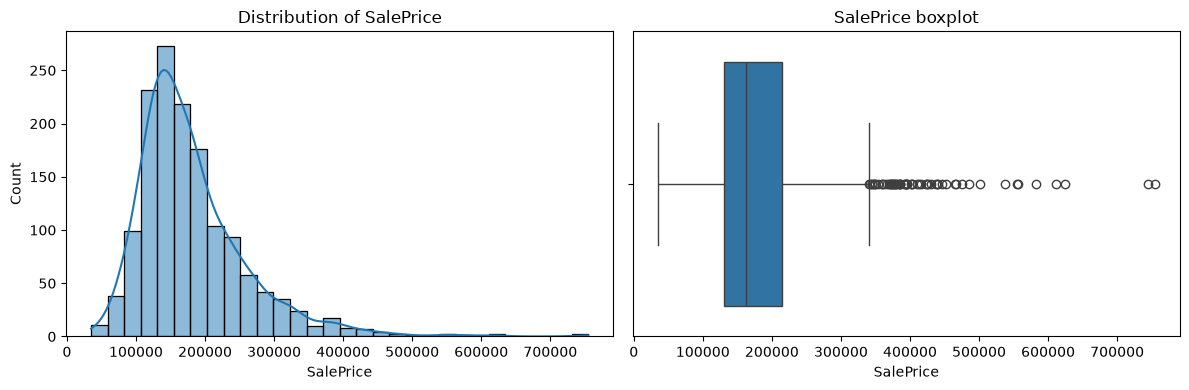

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of SalePrice")
sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice boxplot")
plt.tight_layout()
plt.show()

5 Explore Relationship with sales price

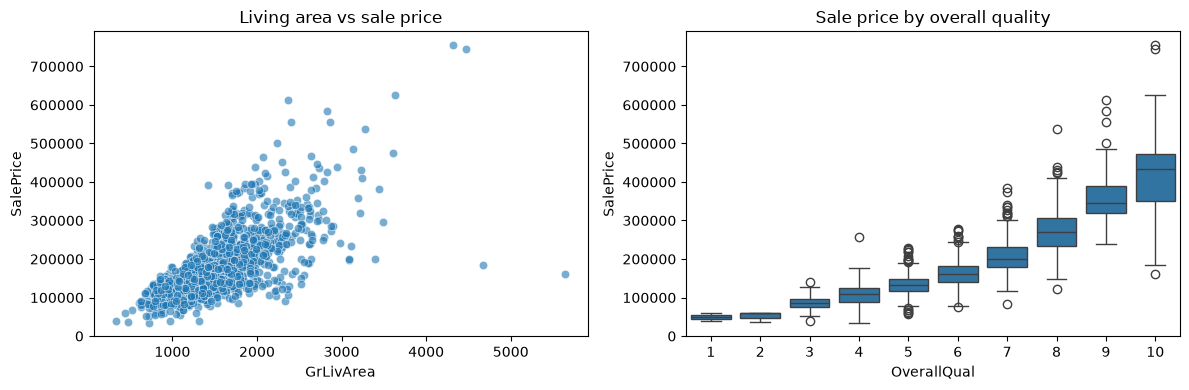

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.6, ax=axes[0])
axes[0].set_title("Living area vs sale price")
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=axes[1])
axes[1].set_title("Sale price by overall quality")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

6 Correlation Analysis

In [15]:
numeric_df = df.select_dtypes(include="number")
corr_with_price = numeric_df.corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
display(corr_with_price.head(15).to_frame("correlation_with_SalePrice"))

,correlation_with_SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


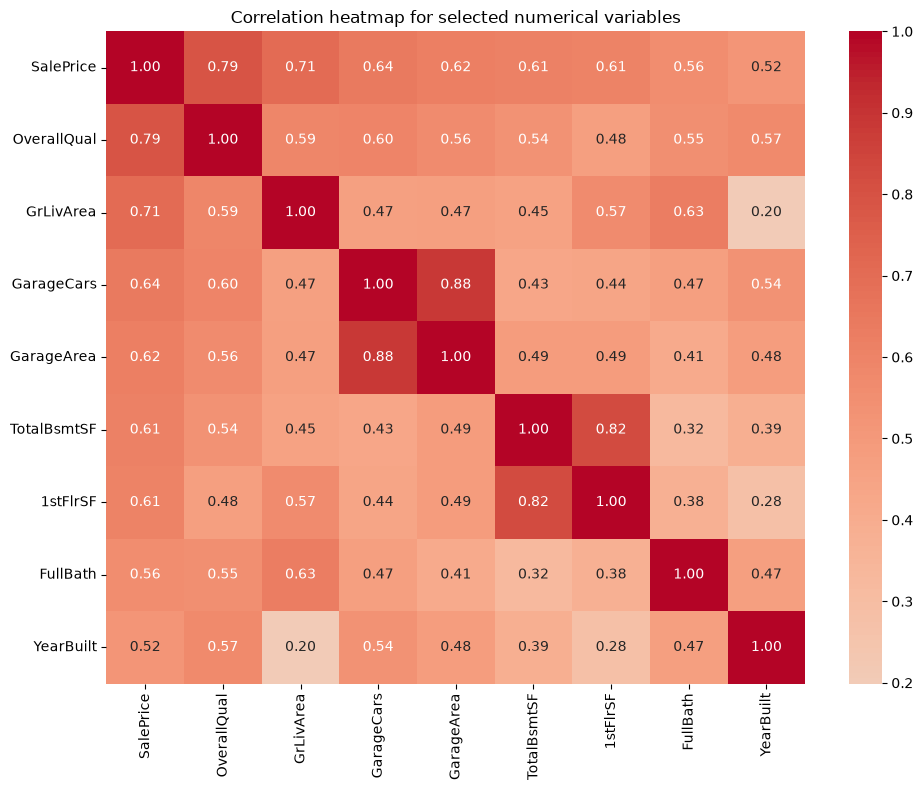

In [16]:
plt.figure(figsize=(10, 8))
selected = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars",
            "GarageArea", "TotalBsmtSF", "1stFlrSF", "FullBath", "YearBuilt"]
sns.heatmap(df[selected].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap for selected numerical variables")
plt.tight_layout()
plt.show()

7 Compare sales price by overall quality

In [17]:
quality_summary = df.groupby("OverallQual")["SalePrice"].agg(
    homes="count", mean_sale_price="mean", median_sale_price="median"
).round(0)
display(quality_summary)

,homes,mean_sale_price,median_sale_price
OverallQual,,,
1,2,50150.0,50150.0
2,3,51770.0,60000.0
3,20,87474.0,86250.0
4,116,108421.0,108000.0
5,397,133523.0,133000.0
6,374,161603.0,160000.0
7,319,207716.0,200141.0
8,168,274736.0,269750.0
9,43,367513.0,345000.0
